# Salary Prediction

An HR team wants to estimate a candidate's salary from three inputs: years of experience, written test score and interview score. This notebook explores the data and explains how well the model works. The reusable code lives in the `salary_model` package.

In [1]:
import sys
sys.path.insert(0, '..')

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import KFold, cross_val_predict

from salary_model.features import FEATURES, TARGET, parse_experience
from salary_model.predict import predict_salaries
from salary_model.train import build_pipeline, cross_validated_scores

## 1. Load the data

In [2]:
df = pd.read_csv('../data/input_dataset.csv')
df.head()

,experience,test_score,interview_score,salary
0,four,7.0,8,60000
1,NaN,8.0,6,45000
2,six,7.0,6,63000
3,two,9.0,9,63000
4,seven,9.0,8,70000


## 2. Data quality

Experience is written as words, and some values are missing. Blank experience is treated as zero years, and missing test scores use the training median. Identical rows are kept because two candidates can genuinely share the same scores on such small scales, and results are also reported without them.

In [3]:
pd.DataFrame({'missing': df.isnull().sum()}).assign(duplicate_rows=lambda t: [int(df.duplicated().sum())] + [''] * (len(t) - 1))

,missing,duplicate_rows
experience,6,8
test_score,3,
interview_score,0,
salary,0,


In [4]:
blank = df[df['experience'].isnull()]['salary'].mean()
one_year = df[df['experience'] == 'one']['salary'].mean()
print(f'Average salary, blank experience: {blank:,.0f}')
print(f'Average salary, one year:         {one_year:,.0f}')

Average salary, blank experience: 49,167
Average salary, one year:         49,750


## 3. Explore the relationships

Experience has the strongest link with salary.

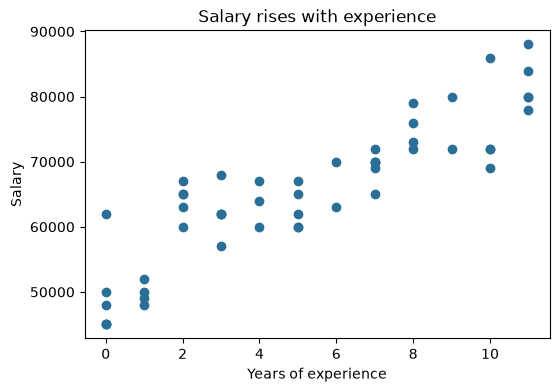

In [5]:
years = df['experience'].map(parse_experience)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(years, df[TARGET], color='#2a6f97')
ax.set_xlabel('Years of experience')
ax.set_ylabel('Salary')
ax.set_title('Salary rises with experience')
plt.show()

## 4. Fit the model

The pipeline parses experience, fills missing scores using medians learned from the training data, and fits a linear regression.

In [6]:
model = build_pipeline().fit(df[FEATURES], df[TARGET])
regression = model.named_steps['regression']
pd.Series(regression.coef_, index=FEATURES, name='salary change per unit').round(1).to_frame()

,salary change per unit
experience,2750.6
test_score,1021.2
interview_score,2507.4


## 5. Measure it on unseen rows

A score on the training data is optimistic because the model has already seen those rows. Repeated 5-fold cross-validation tests each row on a model that did not train on it.

In [7]:
pd.DataFrame({
    'training data': {'r2': round(model.score(df[FEATURES], df[TARGET]), 3)},
    'cross-validated': cross_validated_scores(df),
    'cross-validated, no duplicates': cross_validated_scores(df.drop_duplicates()),
}).T

,r2,r2_std,mae
training data,0.931,NaN,NaN
cross-validated,0.893,0.083,2338.0
"cross-validated, no duplicates",0.868,0.103,2459.0


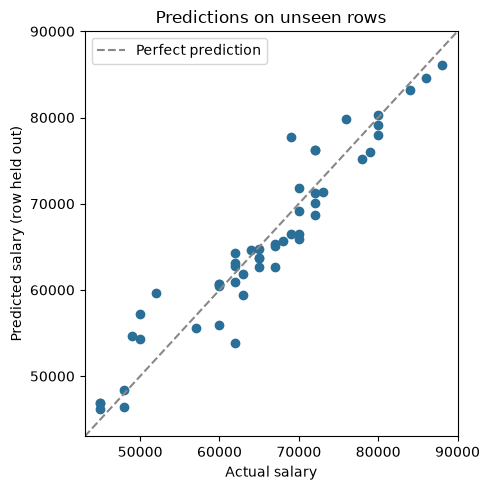

In [8]:
held_out = cross_val_predict(build_pipeline(), df[FEATURES], df[TARGET], cv=KFold(5, shuffle=True, random_state=0))
limits = [df[TARGET].min() - 2000, df[TARGET].max() + 2000]
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df[TARGET], held_out, color='#2a6f97')
ax.plot(limits, limits, color='#888888', linestyle='--', label='Perfect prediction')
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel('Actual salary')
ax.set_ylabel('Predicted salary (row held out)')
ax.set_title('Predictions on unseen rows')
ax.legend()
fig.tight_layout()
fig.savefig('../docs/images/predicted_vs_actual.png', dpi=130)
plt.show()

## 6. Predict for new candidates

In [9]:
new_candidates = pd.read_csv('../data/hiring_test.csv')
predict_salaries(new_candidates, model)

,experience,test_score,interview_score,predicted_salary
0,five,5.0,6,56811
1,two,7.0,5,48094
2,seven,9.0,9,73919
3,NaN,6.0,9,51601
4,three,6.0,8,57345
5,ten,10.0,10,85699
6,NaN,NaN,7,48629
7,eleven,9.0,8,82414


## Limitations

The dataset has only 51 rows and three inputs, so treat predictions as rough estimates for this data. They should not be used on their own to set anyone's pay.